<a href="https://colab.research.google.com/github/Rudra-Patel22/Healthcare-stroke-prediction-RUDRA/blob/main/HealthStrokePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Healthcare Stroke Prediction Model
# P4 - Gathering and Preparing the Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Uploading the Kaggle dataset

from google.colab import files

uploaded = files.upload()


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv


In [3]:
#Loading the dataset into a Pandas DataFrame

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

#Display the first five records
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
#Check the size of the dataset

print("Dataset shape:", df.shape)

#Display column names and data types
print("\nDataset information:")
df.info()

#Display statistical information
print("\nStatistical summary:")
df.describe()


Dataset shape: (5110, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Statistical summary:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [5]:
#Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

#Check for duplicate records
print("\nNumber of duplicate records:")
print(df.duplicated().sum())


Missing values in each column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Number of duplicate records:
0


In [6]:
#Create a copy of the original dataset

df = df.copy()

#Remove duplicate records if any exist

df = df.drop_duplicates()

#Remove the ID column because it is not useful
#for predicting stroke risk

df = df.drop(columns=["id"])

#Check the updated dataset

print("Updated dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum())

display(df.head())


Updated dataset shape: (5110, 11)

Remaining missing values:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [7]:
#Separate input features and target variable

X = df.drop(columns=["stroke"])

y = df["stroke"]

#Display the input features

print("Input features:")
print(X.head())

#Display the target variable

print("\nTarget variable:")
print(y.head())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)


Input features:
   gender   age  hypertension  heart_disease ever_married      work_type  \
0    Male  67.0             0              1          Yes        Private   
1  Female  61.0             0              0          Yes  Self-employed   
2    Male  80.0             0              1          Yes        Private   
3  Female  49.0             0              0          Yes        Private   
4  Female  79.0             1              0          Yes  Self-employed   

  Residence_type  avg_glucose_level   bmi   smoking_status  
0          Urban             228.69  36.6  formerly smoked  
1          Rural             202.21   NaN     never smoked  
2          Rural             105.92  32.5     never smoked  
3          Urban             171.23  34.4           smokes  
4          Rural             174.12  24.0     never smoked  

Target variable:
0    1
1    1
2    1
3    1
4    1
Name: stroke, dtype: int64

Feature shape: (5110, 10)
Target shape: (5110,)


In [8]:
#Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Display the sizes of the datasets

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (4088, 10)
Testing features: (1022, 10)

Training target: (4088,)
Testing target: (1022,)


In [9]:
#Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

Categorical features:
['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [10]:
#Prepare numerical data

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Prepare categorical data

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

#Combine both preprocessing pipelines

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [11]:
#Fit preprocessing on training data
#and transform the training data

X_train_prepared = preprocessor.fit_transform(X_train)

#Transform testing data using the same fitted preprocessor

X_test_prepared = preprocessor.transform(X_test)

#Display the prepared data dimensions

print("Prepared training data:", X_train_prepared.shape)
print("Prepared testing data:", X_test_prepared.shape)

print("\nDataset preparation completed successfully!")


Prepared training data: (4088, 21)
Prepared testing data: (1022, 21)

Dataset preparation completed successfully!


In [12]:
#M2 Checking Class Imbalance

print("Number of patients in each category:")

print(y.value_counts())

print("\nPercentage of each category:")

print(y.value_counts(normalize=True) * 100)


Number of patients in each category:
stroke
0    4861
1     249
Name: count, dtype: int64

Percentage of each category:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


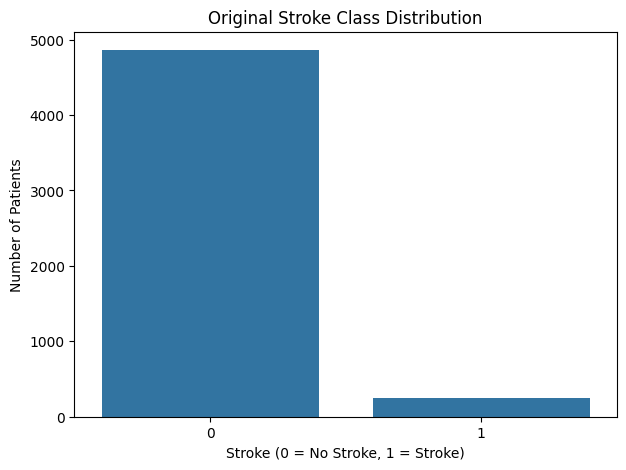

In [13]:
#M2 Visualising the Original Class Distribution

plt.figure(figsize=(7, 5))

sns.countplot(x=y)

plt.title("Original Stroke Class Distribution")
plt.xlabel("Stroke (0 = No Stroke, 1 = Stroke)")
plt.ylabel("Number of Patients")

plt.show()

In [14]:
#M2 Checking Missing Values

print("Missing values in the dataset:")

print(df.isnull().sum())

print("\nTotal missing values:")

print(df.isnull().sum().sum())


Missing values in the dataset:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Total missing values:
201


In [15]:
#M2 Checking Missing Values After Preprocessing

from scipy.sparse import issparse

#Count missing values after preprocessing

if issparse(X_train_prepared):
    missing_after = np.isnan(X_train_prepared.data).sum()
else:
    missing_after = np.isnan(X_train_prepared).sum()

print("Missing values before preprocessing:")
print(df.isnull().sum().sum())

print("\nMissing values after preprocessing:")
print(missing_after)


Missing values before preprocessing:
201

Missing values after preprocessing:
0


In [16]:
#M2 Install Random Oversampling library

!pip install imbalanced-learn

from imblearn.over_sampling import RandomOverSampler

In [17]:
#M2 Apply Random Oversampling

oversampler = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = oversampler.fit_resample(
    X_train_prepared,
    y_train
)

print("Class distribution before balancing:")
print(y_train.value_counts())

print("\nClass distribution after balancing:")
print(y_train_balanced.value_counts())


Class distribution before balancing:
stroke
0    3889
1     199
Name: count, dtype: int64

Class distribution after balancing:
stroke
0    3889
1    3889
Name: count, dtype: int64


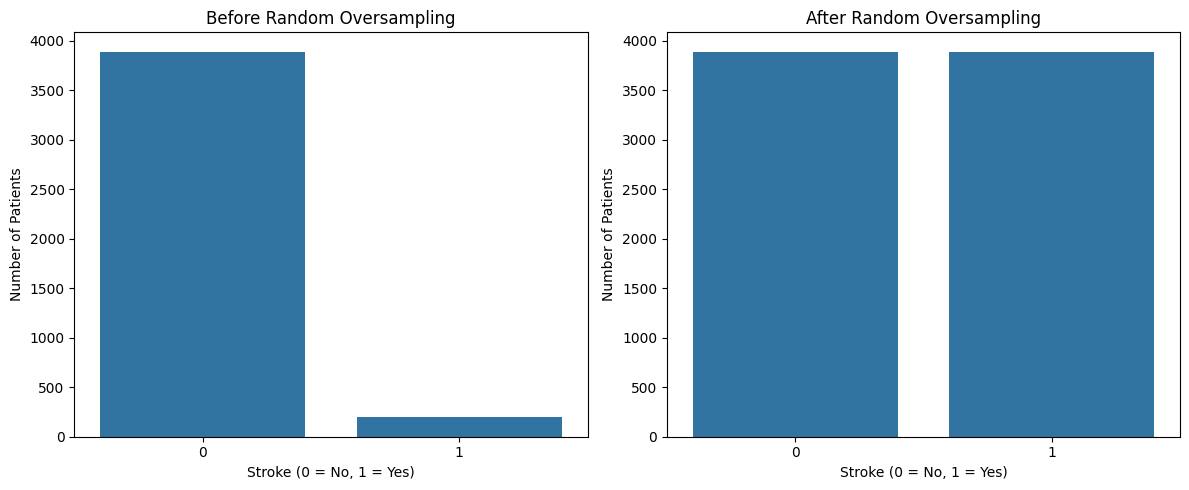

In [18]:
#M2 Compare class distribution before and after balancing

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before Random Oversampling")
axes[0].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of Patients")

sns.countplot(x=y_train_balanced, ax=axes[1])
axes[1].set_title("After Random Oversampling")
axes[1].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[1].set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()


In [19]:
#TRAINING THE INITIAL LOGISTIC REGRESSION MODEL

from sklearn.linear_model import LogisticRegression

#Create the Logistic Regression model
initial_model = LogisticRegression(max_iter=1000, random_state=42)

#Train the model using the prepared training data
initial_model.fit(X_train_prepared, y_train)

print("Initial Logistic Regression model trained successfully.")


Initial Logistic Regression model trained successfully.


In [20]:
#MAKING PREDICTIONS USING THE INITIAL MODEL

#Predict outcomes using the testing data
y_pred_initial = initial_model.predict(X_test_prepared)

#Display the first 20 predictions
print("First 20 predictions:")
print(y_pred_initial[:20])

print("\nPredictions completed successfully.")


First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

Predictions completed successfully.


In [21]:
#EVALUATING THE INITIAL MODEL

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

print("Initial Model Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_initial))
print("Precision:", precision_score(y_test, y_pred_initial, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_initial, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_initial, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_initial, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_initial))


Initial Model Performance
Accuracy: 0.952054794520548
Precision: 1.0
Recall: 0.02
F1 Score: 0.0392156862745098

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022


Confusion Matrix:
[[972   0]
 [ 49   1]]


In [22]:
#TRAINING THE REFINED LOGISTIC REGRESSION MODEL

refined_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

#Train using the balanced training dataset
refined_model.fit(X_train_balanced, y_train_balanced)

print("Refined Logistic Regression model trained successfully.")


Refined Logistic Regression model trained successfully.


In [23]:
#EVALUATING THE REFINED MODEL

#Make predictions using the refined model
y_pred_refined = refined_model.predict(X_test_prepared)

print("Refined Model Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_refined))
print("Precision:", precision_score(y_test, y_pred_refined, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_refined, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_refined, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_refined, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_refined))


Refined Model Performance
Accuracy: 0.7446183953033269
Precision: 0.13745704467353953
Recall: 0.8
F1 Score: 0.23460410557184752

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.82      1022


Confusion Matrix:
[[721 251]
 [ 10  40]]


In [24]:
#COMPARING INITIAL AND REFINED MODELS

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Initial Model": [
        accuracy_score(y_test, y_pred_initial),
        precision_score(y_test, y_pred_initial, zero_division=0),
        recall_score(y_test, y_pred_initial, zero_division=0),
        f1_score(y_test, y_pred_initial, zero_division=0)
    ],
    "Refined Model": [
        accuracy_score(y_test, y_pred_refined),
        precision_score(y_test, y_pred_refined, zero_division=0),
        recall_score(y_test, y_pred_refined, zero_division=0),
        f1_score(y_test, y_pred_refined, zero_division=0)
    ]
})

print(comparison.round(4))


      Metric  Initial Model  Refined Model
0   Accuracy         0.9521         0.7446
1  Precision         1.0000         0.1375
2     Recall         0.0200         0.8000
3   F1 Score         0.0392         0.2346
